# EDA: Оптимизация косметических процессов

**Цель:** Провести разведочный анализ данных (EDA) для датасета, содержащего параметры производства косметики.

**Задачи:**
1. Оценить структуру и полноту данных.
2. Найти выбросы и аномалии.
3. Рассчитать основные метрики.
4. Выявить корреляции между признаками.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline
sns.set_theme(style="whitegrid")

In [2]:
# Загружаем данные (путь "../data/" нужен, так как ноутбук лежит в папке notebooks)
df = pd.read_csv("../data/cosmetic_process_optimisation.csv")

# Выводим первые 5 строк
df.head()

,Batch_ID,Formula_Type,Mixing_Temperature,Viscosity_cP,pH,Stability_Days
0,BATCH_001,Surfactant_Boosted,High_60C,2415.35,6.94,11
1,BATCH_002,Standard,Low_35C,2500.59,6.57,13
2,BATCH_003,Surfactant_Boosted,Low_35C,2013.79,6.84,17
3,BATCH_004,Surfactant_Boosted,High_60C,2398.89,7.12,10
4,BATCH_005,Standard,High_60C,2683.70,6.72,8


In [3]:
print("Размер таблицы:", df.shape)
print("\nТипы данных и пропуски:")
df.info()

Размер таблицы: (120, 6)

Типы данных и пропуски:
<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Batch_ID            120 non-null    str    
 1   Formula_Type        120 non-null    str    
 2   Mixing_Temperature  120 non-null    str    
 3   Viscosity_cP        120 non-null    float64
 4   pH                  120 non-null    float64
 5   Stability_Days      120 non-null    int64  
dtypes: float64(2), int64(1), str(3)
memory usage: 9.3 KB


### Оценка структуры данных
- Датасет содержит **120 строк** и **6 столбцов**.
- Пропусков в данных **нет** (все столбцы имеют 120 non-null значений).
- Типы данных: 2 вещественных (`float64`), 1 целочисленный (`int64`), 3 строковых (`str`).
- Столбец `Mixing_Temperature` содержит текст (High/Low), его нужно привести к числу для анализа корреляций.

In [4]:
# 1. Приводим Mixing_Temperature к числу (извлекаем цифры)
df["Mixing_Temperature"] = df["Mixing_Temperature"].str.extract(r"(\d+)").astype(float)

# 2. Смотрим описательные статистики (среднее, медиана, минимум, максимум)
df.describe()

,Mixing_Temperature,Viscosity_cP,pH,Stability_Days
count,120.000000,120.000000,120.000000,120.000000
mean,46.250000,2769.128417,6.614333,14.816667
std,12.489491,542.491836,0.293818,3.595009
min,35.000000,1849.630000,6.060000,6.000000
25%,35.000000,2372.517500,6.390000,13.000000
50%,35.000000,2636.640000,6.575000,15.000000
75%,60.000000,3300.845000,6.850000,17.000000
max,60.000000,3774.290000,7.180000,22.000000


In [5]:
# Возвращаем категориальный признак для температуры
df["Mixing_Temperature_C"] = df["Mixing_Temperature"].apply(lambda x: "High_60C" if x >= 60 else "Low_35C")
df["Mixing_Temperature_C"] = df["Mixing_Temperature_C"].astype("category")

# Проверяем, что получилось
print(df["Mixing_Temperature_C"].value_counts())

Mixing_Temperature_C
Low_35C     66
High_60C    54
Name: count, dtype: int64


### Основные метрики
- **Вязкость (Viscosity_cP):** среднее значение ~2769, минимум 1849, максимум 3774. Разброс достаточно большой.
- **pH:** среднее ~6.61, значения варьируются от 6.06 до 7.18. Среда близка к нейтральной.
- **Стабильность (Stability_Days):** в среднем 14.8 дней, максимум 22 дня.
- **Температура (Mixing_Temperature):** от 35 до 60 градусов.

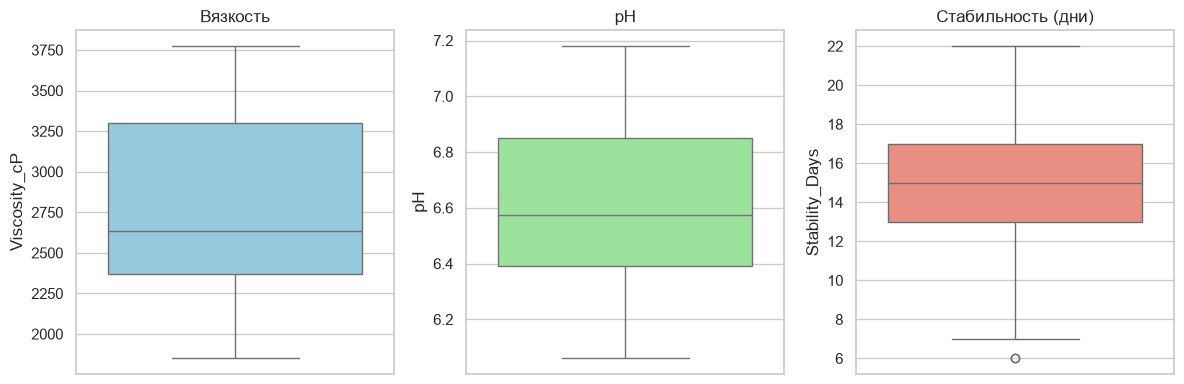

In [6]:
# Строим коробчатые диаграммы для поиска выбросов
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
sns.boxplot(y=df["Viscosity_cP"], color="skyblue")
plt.title("Вязкость")

plt.subplot(1, 3, 2)
sns.boxplot(y=df["pH"], color="lightgreen")
plt.title("pH")

plt.subplot(1, 3, 3)
sns.boxplot(y=df["Stability_Days"], color="salmon")
plt.title("Стабильность (дни)")

plt.tight_layout()
plt.show()

In [7]:
# Поиск выбросов по правилу 1.5 IQR
numeric_cols = ["Viscosity_cP", "pH", "Stability_Days"]
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    if len(outliers) > 0:
        print(f"{col}: найдено {len(outliers)} выбросов")
        print(outliers[[col]])
    else:
        print(f"{col}: выбросов нет")

Viscosity_cP: выбросов нет
pH: выбросов нет
Stability_Days: найдено 2 выбросов
    Stability_Days
38               6
87               6


### Выбросы и аномалии
- По графику и по правилу 1.5 IQR видно, что в столбце Stability_Days есть 2 выброса (значение 6 дней).
- В остальных столбцах (Вязкость и pH) выбросов нет.
- Эти аномалии относятся к партиям **BATCH_039** и **BATCH_088**. Срок стабильности 6 дней — это очень мало по сравнению со средним (около 15 дней). 
- Если посмотреть на их условия, видно, что оба выброса приходятся на температуру High_60C. Это согласуется с нашей гипотезой о том, что высокая температура негативно влияет на стабильность. Удалять эти строки я не стала, чтобы технолог мог изучить эти партии.

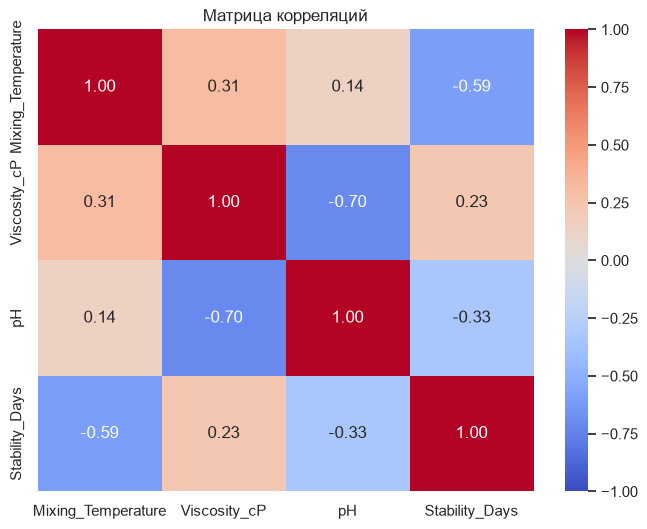

In [8]:
# Строим матрицу корреляций для числовых признаков
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=['float64', 'int64']).corr(), 
            annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Матрица корреляций")
plt.show()

### Анализ корреляций
- **Вязкость и pH (-0.70):** обнаружена сильная отрицательная корреляция. Это означает, что при повышении уровня pH вязкость продукта заметно снижается.
- **Температура смешивания и стабильность (-0.59):** умеренная обратная связь. Проведение процесса при высокой температуре (60°C) негативно сказывается на сроке хранения продукта, это подтверждается матрицей корреляций.
- Между вязкостью и стабильностью связь слабая положительная (0.23), а между pH и стабильностью — слабая отрицательная (-0.33).